# Manutenção Preditiva de Motores Industriais (IO-Link)

Detecção de anomalias de operação, alerta de desvios e recomendação de manutenção
a partir de dados históricos de dois motores (velocidade, aceleração e temperatura).

**Estrutura do notebook**
1. Carga e limpeza dos dados
2. Análise exploratória (EDA)
3. Engenharia de atributos
4. Treino da linha de base saudável
5. Detecção de anomalia + Índice de Saúde + alerta de manutenção
6. Demonstração: motor saudável vs. degradação injetada
7. Conclusões, limitações e próximos passos

> **Metodologia.** Como os dados não possuem rótulos de falha, usamos detecção de anomalia
> *não supervisionada*: o modelo aprende o comportamento **normal** a partir de um histórico
> saudável e mede o quanto cada novo ponto se afasta dessa referência.

## 0. Configuração

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# >>> Ajuste o caminho para o seu arquivo CSV <<<
PATH = "../data/History_32026-05-19T11-46-10-920.csv"

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Carga e limpeza

O arquivo é um log IO-Link separado por `;` com 3 linhas de cabeçalho. As colunas úteis são
o timestamp e as 6 medições (velocidade, aceleração e temperatura de cada motor).
Os *byte arrays* brutos são apenas a versão crua dessas mesmas medições — descartados aqui.

In [2]:
def load(path=PATH):
    df = pd.read_csv(path, sep=";", header=None, skiprows=3)
    df.columns = ["timestamp","p1_bytes","p2_bytes",
                  "m1_vel","m1_acc","m1_temp","m2_vel","m2_acc","m2_temp"]
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    for c in ["m1_vel","m1_acc","m1_temp","m2_vel","m2_acc","m2_temp"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.sort_values("timestamp").reset_index(drop=True)

raw = load()
print("Registros:", len(raw))
print("Período :", raw.timestamp.min(), "->", raw.timestamp.max())
print("Duração :", raw.timestamp.max() - raw.timestamp.min())
raw.head()

Registros: 7183
Período : 2026-05-19 11:46:10.921000 -> 2026-05-19 15:43:14.082000
Duração : 0 days 03:57:03.161000


,timestamp,p1_bytes,p2_bytes,m1_vel,m1_acc,m1_temp,m2_vel,m2_acc,m2_temp
0,2026-05-19 11:46:10.921,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.040,0.000,27,0.040,0.000,34
1,2026-05-19 11:46:11.290,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.040,0.000,27,0.040,0.000,34
2,2026-05-19 11:46:14.920,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.040,0.000,27,0.040,0.000,34
3,2026-05-19 11:46:15.296,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.040,0.000,27,0.030,0.000,34
4,2026-05-19 11:46:21.919,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.040,0.000,27,0.030,0.000,34


## 2. Análise exploratória (EDA)

In [3]:
num = ["m1_vel","m1_acc","m1_temp","m2_vel","m2_acc","m2_temp"]
display(raw[num].describe().T[["mean","std","min","25%","50%","75%","max"]])

print("Valores nulos:"); print(raw[num].isna().sum().to_string())
print("\nIntervalo entre amostras (s):")
dt = raw.timestamp.diff().dt.total_seconds().dropna()
print(dt.describe()[["mean","min","50%","max"]].to_string())

,mean,std,min,25%,50%,75%,max
m1_vel,2.500,2.895,0.030,0.040,0.640,6.380,7.460
m1_acc,0.187,0.223,0.000,0.000,0.040,0.480,0.580
m1_temp,31.936,4.594,27.000,28.000,31.000,34.000,46.000
m2_vel,2.619,2.995,0.030,0.040,0.740,6.430,7.730
m2_acc,0.190,0.226,0.000,0.000,0.040,0.470,0.600
m2_temp,37.396,3.614,33.000,35.000,36.000,39.000,47.000


Valores nulos:
m1_vel     0
m1_acc     0
m1_temp    0
m2_vel     0
m2_acc     0
m2_temp    0

Intervalo entre amostras (s):
mean     1.980
min      0.000
50%      0.595
max    228.381


### 2.1 Correlação entre as variáveis

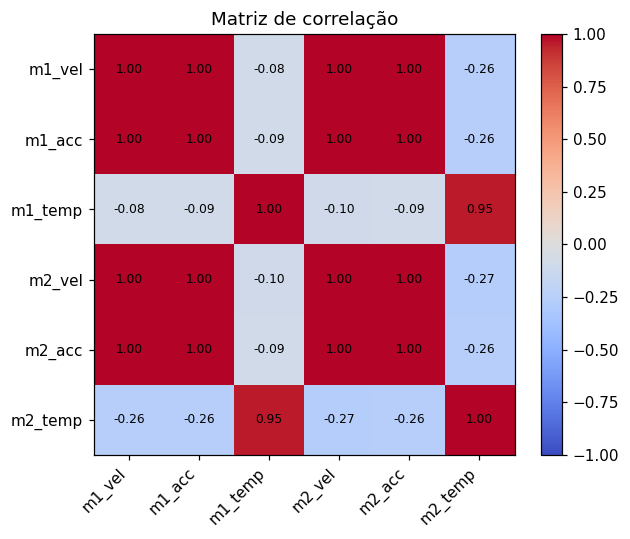

In [4]:
corr = raw[num].corr()
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, fraction=0.046); ax.set_title("Matriz de correlação"); plt.tight_layout(); plt.show()

**Leitura da correlação**
- Velocidade e aceleração são quase redundantes (~0.99) — uma deriva da outra.
- Os dois motores andam praticamente juntos (velocidade ~0.998, temperatura ~0.95): sistema acoplado.
- Temperatura tem correlação *instantânea* baixa/negativa com velocidade — sinal de **inércia térmica** (a temperatura atrasa em relação à carga).

### 2.2 Panorama visual

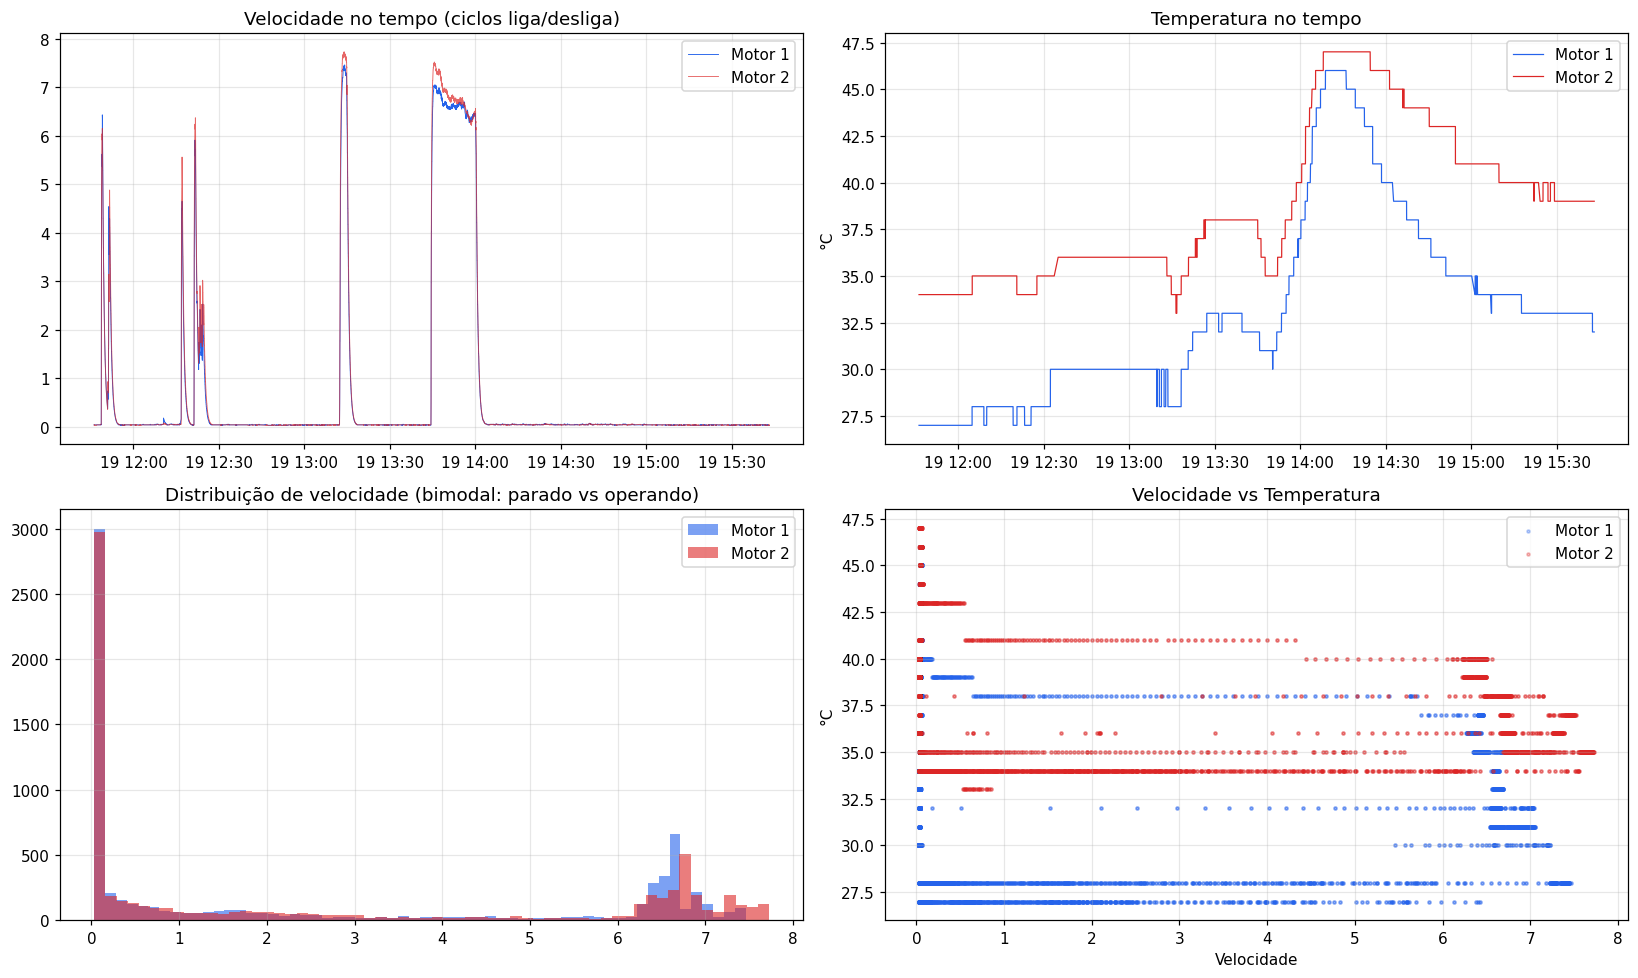

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ax[0,0].plot(raw.timestamp, raw.m1_vel, lw=.6, color="#2563eb", label="Motor 1")
ax[0,0].plot(raw.timestamp, raw.m2_vel, lw=.6, color="#dc2626", alpha=.7, label="Motor 2")
ax[0,0].set_title("Velocidade no tempo (ciclos liga/desliga)"); ax[0,0].legend(); ax[0,0].grid(alpha=.3)

ax[0,1].plot(raw.timestamp, raw.m1_temp, lw=.8, color="#2563eb", label="Motor 1")
ax[0,1].plot(raw.timestamp, raw.m2_temp, lw=.8, color="#dc2626", label="Motor 2")
ax[0,1].set_title("Temperatura no tempo"); ax[0,1].set_ylabel("°C"); ax[0,1].legend(); ax[0,1].grid(alpha=.3)

ax[1,0].hist(raw.m1_vel, bins=60, alpha=.6, color="#2563eb", label="Motor 1")
ax[1,0].hist(raw.m2_vel, bins=60, alpha=.6, color="#dc2626", label="Motor 2")
ax[1,0].set_title("Distribuição de velocidade (bimodal: parado vs operando)")
ax[1,0].legend(); ax[1,0].grid(alpha=.3)

ax[1,1].scatter(raw.m1_vel, raw.m1_temp, s=4, alpha=.3, color="#2563eb", label="Motor 1")
ax[1,1].scatter(raw.m2_vel, raw.m2_temp, s=4, alpha=.3, color="#dc2626", label="Motor 2")
ax[1,1].set_title("Velocidade vs Temperatura"); ax[1,1].set_xlabel("Velocidade"); ax[1,1].set_ylabel("°C")
ax[1,1].legend(); ax[1,1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Principais achados da EDA**
- **Estados discretos**: a velocidade é bimodal (parado ≈ 0 / operando ≈ 6.5–7.5). Não há um contínuo de velocidades.
- **Inércia térmica**: a temperatura sobe e atinge o pico (~46–47°C) *depois* da operação pesada, e esfria lentamente por mais de 1h.
- **Acoplamento M1–M2**: os dois motores sobem e descem juntos; uma divergência entre eles é, por si só, um forte indício de anomalia.

## 3. Engenharia de atributos

Reamostramos para uma grade fixa (10s) e criamos atributos que capturam dinâmica:
estatísticas móveis, taxa de variação da temperatura, *duty cycle* e a divergência entre os dois motores.

In [6]:
def to_series(df):
    return df.set_index("timestamp")[["m1_vel","m1_temp","m2_vel","m2_temp"]]

def resample(df, rule="10s"):
    return df.resample(rule).mean().interpolate(limit=6).ffill().bfill()

def features(r, win=12):  # 12 x 10s = 2 min
    f = pd.DataFrame(index=r.index)
    for m in ["m1","m2"]:
        v, t = r[f"{m}_vel"], r[f"{m}_temp"]
        f[f"{m}_vel"] = v
        f[f"{m}_temp"] = t
        f[f"{m}_vel_std"]  = v.rolling(win, min_periods=1).std().fillna(0)
        f[f"{m}_temp_rate"]= t.diff().rolling(win, min_periods=1).mean().fillna(0)
        f[f"{m}_duty"]     = (v > 1.0).rolling(win, min_periods=1).mean()
    f["temp_div"] = r["m1_temp"] - r["m2_temp"]   # acoplamento
    f["vel_div"]  = r["m1_vel"]  - r["m2_vel"]
    return f.fillna(0)

def _thermal_feat(r, m):
    v = r[f"{m}_vel"]
    return pd.DataFrame({
        "vel": v, "vel_lag": v.shift(6).fillna(0),
        "work_3min": v.rolling(18, min_periods=1).mean(),
        "work_6min": v.rolling(36, min_periods=1).mean(),
    }, index=r.index)

r_demo = resample(to_series(raw))
features(r_demo).head()

,m1_vel,m1_temp,m1_vel_std,m1_temp_rate,m1_duty,m2_vel,m2_temp,m2_vel_std,m2_temp_rate,m2_duty,temp_div,vel_div
timestamp,,,,,,,,,,,,
2026-05-19 11:46:10,0.040,27.000,0.000,0.000,0.000,0.037,34.000,0.000,0.000,0.000,-7.000,0.003
2026-05-19 11:46:20,0.040,27.000,0.000,0.000,0.000,0.035,34.000,0.002,0.000,0.000,-7.000,0.005
2026-05-19 11:46:30,0.040,27.000,0.000,0.000,0.000,0.035,34.000,0.001,0.000,0.000,-7.000,0.005
2026-05-19 11:46:40,0.040,27.000,0.000,0.000,0.000,0.035,34.000,0.001,0.000,0.000,-7.000,0.005
2026-05-19 11:46:50,0.040,27.000,0.000,0.000,0.000,0.035,34.000,0.001,0.000,0.000,-7.000,0.005


## 4. Treino da linha de base saudável

`fit_baseline` aprende o comportamento normal:
- **Isolation Forest** sobre os atributos de operação (detecta pontos atípicos).
- **Modelo térmico (Ridge)** que prevê a temperatura *esperada* dada a carga — o resíduo (real − esperado) sinaliza aquecimento não explicado.
- **Calibração** da fronteira do normal a partir dos próprios dados saudáveis.

In [7]:
def fit_baseline(df_healthy):
    r = resample(to_series(df_healthy)); f = features(r)
    scaler = StandardScaler().fit(f)
    iso = IsolationForest(n_estimators=300, random_state=42).fit(scaler.transform(f))
    score = -iso.score_samples(scaler.transform(f))
    thermal = {m: Ridge(alpha=1.0).fit(_thermal_feat(r, m), r[f"{m}_temp"]) for m in ["m1","m2"]}
    resid = pd.DataFrame({m: r[f"{m}_temp"] - thermal[m].predict(_thermal_feat(r, m)) for m in ["m1","m2"]})
    cal = {"ref": np.percentile(score, 99.6), "smax": score.max(),
           "rstd": resid.abs().stack().std() + 1e-6, "cols": f.columns}
    return {"scaler": scaler, "iso": iso, "thermal": thermal, "cal": cal}

model = fit_baseline(raw)
print("Modelo treinado. Fronteira do normal (score ref):", round(model["cal"]["ref"], 3))

Modelo treinado. Fronteira do normal (score ref): 0.692


## 5. Score, Índice de Saúde e alerta de manutenção

`score` aplica o modelo a dados novos e devolve o **Índice de Saúde (0–100)**.
A penalidade só cresce **além da fronteira do normal**, então dados saudáveis ficam perto de 100.
O alerta de manutenção dispara quando a saúde fica abaixo do limiar de forma **sustentada**.

In [8]:
def score(df_new, model):
    r = resample(to_series(df_new)); f = features(r)[model["cal"]["cols"]]
    sc = -model["iso"].score_samples(model["scaler"].transform(f))
    resid = pd.DataFrame({m: r[f"{m}_temp"] - model["thermal"][m].predict(_thermal_feat(r, m))
                          for m in ["m1","m2"]}, index=r.index)
    cal = model["cal"]
    s_pen = np.clip((sc - cal["ref"]) / (cal["smax"] - cal["ref"] + 1e-9), 0, 1)
    rmax  = resid.abs().max(axis=1).values
    r_pen = np.clip((rmax - 3*cal["rstd"]) / (4*cal["rstd"]), 0, 1)  # >3σ penaliza
    penalty = 1 - (1 - s_pen) * (1 - r_pen)                          # OR probabilístico
    health = pd.Series(100*(1 - penalty), index=r.index).ewm(alpha=0.03).mean()
    return r, resid, health, maintenance_logic(health)

def maintenance_logic(health, warn=65, crit=45, persist=18):  # persist ~3 min
    h = health.values; idx = health.index; out = []; run = 0
    for i in range(len(h)):
        run = run + 1 if h[i] < warn else 0
        if run == persist:
            out.append((idx[i], "CRÍTICO" if h[i] < crit else "ATENÇÃO", float(h[i])))
    return out

## 6. Demonstração: saudável vs. degradação injetada

Os dados reais não contêm falhas rotuladas, então, para **validar** o detector, injetamos
artificialmente uma degradação no Motor 1 (aquecimento progressivo na fase de resfriamento,
mais instabilidade de velocidade). Isso simula um defeito incipiente — por exemplo, desgaste
de rolamento gerando calor anormal.

In [9]:
# Cenário A: dados reais (assumidos saudáveis)
rA, residA, healthA, alertsA = score(raw, model)

# Cenário B: degradação injetada no Motor 1
dfB = raw.copy(); n = len(dfB); s0 = int(n*0.72)
ramp = np.zeros(n); ramp[s0:] = np.linspace(0, 11, n-s0)
dfB["m1_temp"] = dfB["m1_temp"] + ramp
np.random.seed(1); nz = np.zeros(n); k = int(n*0.88)
nz[k:] = np.random.normal(0, 0.7, n-k)
dfB["m1_vel"] = (dfB["m1_vel"] + nz).clip(lower=0)
onset = dfB.timestamp.iloc[s0]

rB, residB, healthB, alertsB = score(dfB, model)

print("A) DADOS REAIS (saudável)")
print("   saúde min/média:", round(healthA.min(),1), "/", round(healthA.mean(),1), "| alertas:", len(alertsA))
print("B) DEGRADAÇÃO INJETADA EM M1")
print("   início da falha :", onset)
print("   saúde min/média :", round(healthB.min(),1), "/", round(healthB.mean(),1), "| alertas:", len(alertsB))
for t0, lvl, h in alertsB:
    print(f"   >>> ALERTA {t0} [{lvl}] saúde={h:.0f}  ({(t0-onset).total_seconds()/60:.0f} min após o início)")

A) DADOS REAIS (saudável)
   saúde min/média: 66.0 / 97.2 | alertas: 0
B) DEGRADAÇÃO INJETADA EM M1
   início da falha : 2026-05-19 13:59:15.905000
   saúde min/média : 36.9 / 91.0 | alertas: 1
   >>> ALERTA 2026-05-19 14:12:30 [ATENÇÃO] saúde=50  (13 min após o início)


### 6.1 Dashboard comparativo

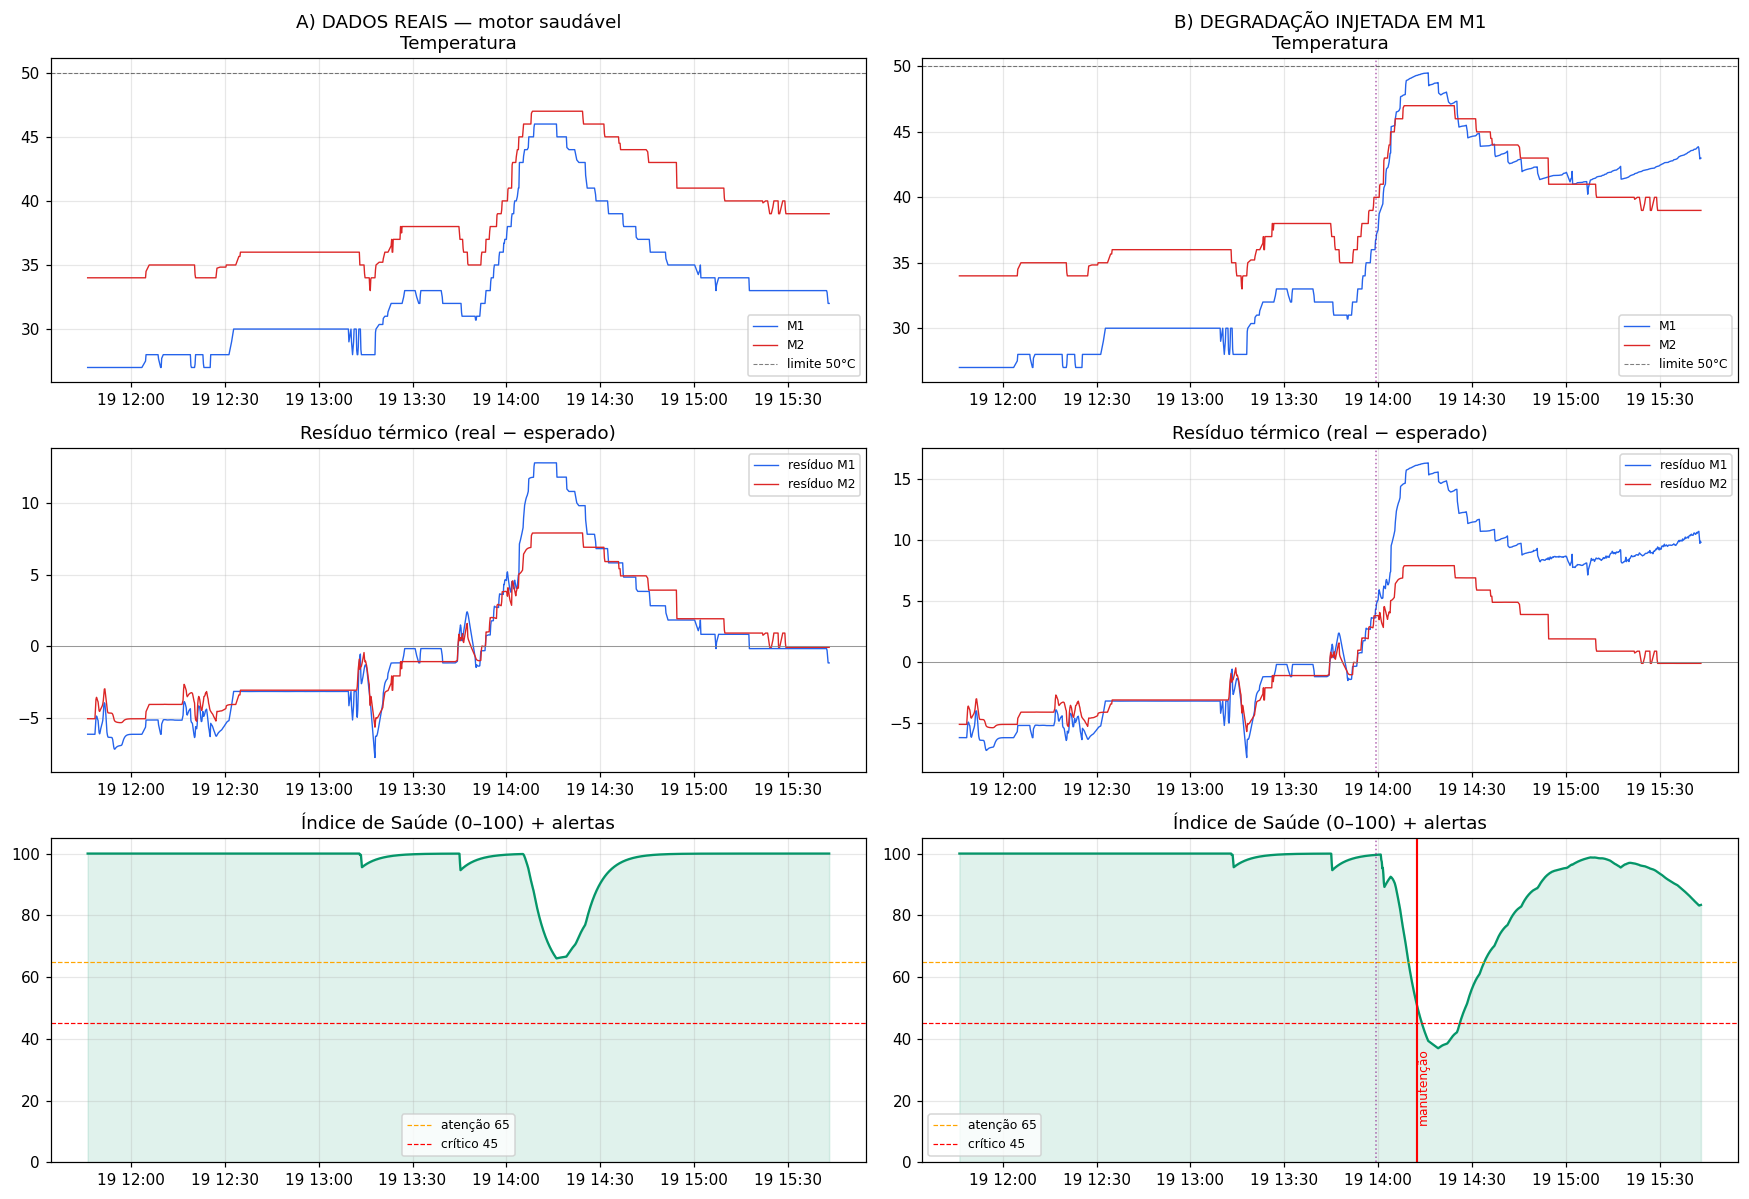

In [10]:
fig, ax = plt.subplots(3, 2, figsize=(16, 11))
panels = [(rA, residA, healthA, alertsA, "A) DADOS REAIS — motor saudável", None),
          (rB, residB, healthB, alertsB, "B) DEGRADAÇÃO INJETADA EM M1", onset)]
for col, (r, resid, health, alerts, ttl, mark) in enumerate(panels):
    ax[0,col].plot(r.index, r.m1_temp, color="#2563eb", lw=.9, label="M1")
    ax[0,col].plot(r.index, r.m2_temp, color="#dc2626", lw=.9, label="M2")
    ax[0,col].axhline(50, color="k", ls="--", lw=.7, alpha=.5, label="limite 50°C")
    ax[0,col].set_title(f"{ttl}\nTemperatura"); ax[0,col].legend(fontsize=8); ax[0,col].grid(alpha=.3)

    ax[1,col].plot(r.index, resid.m1, color="#2563eb", lw=.9, label="resíduo M1")
    ax[1,col].plot(r.index, resid.m2, color="#dc2626", lw=.9, label="resíduo M2")
    ax[1,col].axhline(0, color="gray", lw=.5)
    ax[1,col].set_title("Resíduo térmico (real − esperado)"); ax[1,col].legend(fontsize=8); ax[1,col].grid(alpha=.3)

    ax[2,col].plot(r.index, health, color="#059669", lw=1.5)
    ax[2,col].axhline(65, color="orange", ls="--", lw=.8, label="atenção 65")
    ax[2,col].axhline(45, color="red", ls="--", lw=.8, label="crítico 45")
    ax[2,col].fill_between(r.index, 0, health, color="#059669", alpha=.12)
    for t0, lvl, h in alerts:
        ax[2,col].axvline(t0, color="red", lw=1.4)
        ax[2,col].annotate("manutenção", (t0, 12), fontsize=8, color="red", rotation=90, va="bottom")
    if mark is not None:
        for row in range(3): ax[row,col].axvline(mark, color="purple", ls=":", lw=1, alpha=.6)
    ax[2,col].set_ylim(0,105); ax[2,col].set_title("Índice de Saúde (0–100) + alertas")
    ax[2,col].legend(fontsize=8); ax[2,col].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Resultado.** No motor saudável, o índice fica próximo de 100 sem alarmes falsos. Na
degradação injetada, a saúde despenca e o alerta de manutenção dispara poucos minutos após o
início do defeito — **mesmo sem a temperatura cruzar o limite absoluto de 50°C**, algo que um
alarme de limite fixo tradicional não detectaria.

## 7. Conclusões, limitações e próximos passos

**O que este notebook entrega**
- Análise exploratória completa dos dados de operação.
- Detector de anomalia não supervisionado treinado na linha de base saudável.
- Índice de Saúde contínuo (0–100) e lógica de alerta de manutenção configurável.
- Validação com falha injetada mostrando a detecção precoce.

**Limitações honestas**
- *Sem rótulos de falha*: não dá para prever **Vida Útil Remanescente (RUL)** — "faltam X horas para falhar".
  Isso exige histórico de degradação até a falha (*run-to-failure*) ou registros de manutenção.
- *Pouca história*: ~4 h de uma única sessão cobrem poucos regimes normais; a robustez melhora muito
  com semanas/meses de dados.
- *Resolução*: temperatura em passos de 1°C e amostragem irregular limitam a sensibilidade fina.
- *Vibração*: a aceleração está agregada (~0.6 s), insuficiente para análise espectral (FFT) de rolamentos.

**Próximos passos**
1. Rodar `score()` em streaming conforme os dados chegam do IO-Link (monitoramento em tempo real).
2. Registrar eventos reais de manutenção/falha para, com o tempo, treinar modelos de RUL (LSTM, gradient boosting, análise de sobrevivência).
3. Calibrar os limiares de alerta junto à equipe de manutenção.
4. Se o objetivo for falha de rolamento, coletar vibração em alta frequência para features espectrais.